In [1]:
import numpy as np
import matplotlib.pyplot as plt

In [2]:
from spp_extended_theory.Libs.libMaterials import *
from spp_extended_theory.Libs.libImportOpticalData import *

In [3]:
epsAir=1.
NumWavelengths=300
wavelengths = np.linspace(200e-9, 1.2e-6, NumWavelengths)

In [4]:
folder="/home/thibault.derrien/Documents/spp-extended-theory/spp_extended_theory/SimpleSPP/Database/"
filename="Tikuisis2023-Fig4"

** Info: opening /home/thibault.derrien/Documents/spp-extended-theory/spp_extended_theory/SimpleSPP/Database/Tikuisis2023-Fig4-epsR.csv and /home/thibault.derrien/Documents/spp-extended-theory/spp_extended_theory/SimpleSPP/Database/Tikuisis2023-Fig4-epsC.csv.
** Info: Generating the new wavelength mesh: (5.2531e-07, 5.4993800000000005e-06)
New wavelength mesh has 10000 rows.
** Info: definition of interpolation functions...

importFromEpsilonTable: Interpolated permittivity at [ 200.          203.34448161  206.68896321  210.03344482  213.37792642
  216.72240803  220.06688963  223.41137124  226.75585284  230.10033445
  233.44481605  236.78929766  240.13377926  243.47826087  246.82274247
  250.16722408  253.51170569  256.85618729  260.2006689   263.5451505
  266.88963211  270.23411371  273.57859532  276.92307692  280.26755853
  283.61204013  286.95652174  290.30100334  293.64548495  296.98996656
  300.33444816  303.67892977  307.02341137  310.36789298  313.71237458
  317.05685619  320.40

findfont: Font family ['sans-serif'] not found. Falling back to DejaVu Sans.
The PostScript backend does not support transparency; partially transparent artists will be rendered opaque.
The PostScript backend does not support transparency; partially transparent artists will be rendered opaque.


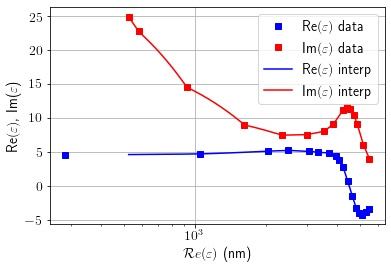

In [5]:
epsGrSiO2 = importFromEpsilonTable(wavelengths, folder, filename, plotting=1, unit=1E-6)

# Compute absorptivity

In [6]:
alpha = 4*np.pi/wavelengths * np.sqrt(epsGrSiO2).imag

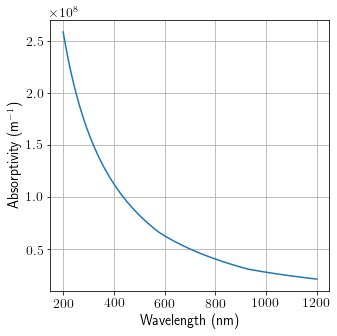

In [16]:
plt.figure(figsize=(5,5))
plt.plot(1E9*wavelengths, alpha, '-')
plt.xlabel("Wavelength (nm)")
plt.ylabel(r"Absorptivity (m$^{-1}$)")
plt.grid()
plt.savefig("Tikuisis2023-Absorptivity.png")
plt.show()

/home/thibault.derrien/.local/lib/python3.6/site-packages/numpy/core/_asarray.py:83: ComplexWarning: Casting complex values to real discards the imaginary part
  return array(a, dtype, copy=False, order=order)


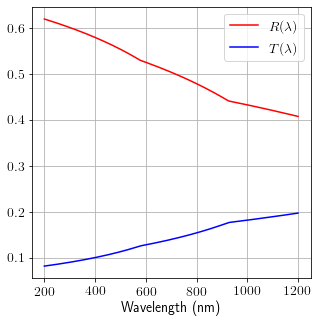

In [29]:
R=reflectivity(1, epsGrSiO2)
T=ComplexTransmission(1,epsGrSiO2)
plt.figure(figsize=(5,5))
plt.plot(1E9*wavelengths, R, '-r', label=r'$R(\lambda)$')
plt.plot(1E9*wavelengths, T*np.conj(T), '-b', label=r'$T(\lambda)$')
plt.xlabel("Wavelength (nm)")
plt.legend(loc="best")
plt.grid()
plt.savefig("Tikuisis2023-Reflectivity-Transmission.png")
plt.show()